In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [28]:
g = 9.81          
k = 0.5405         
m = 0.43           # (citation chaiyo)

v0 = [30.405, 9.122, 6.933] 
r0 = [0.0, 0.0, 0.11]

In [29]:
state0 = r0 + v0

In [30]:
def equations_of_motion(t, state):
    x, y, z, vx, vy, vz = state
    
    # Linear drag + gravity accelerations
    ax = -k * vx
    ay = -k * vy
    az = -g - k * vz
    
    return [vx, vy, vz, ax, ay, az]

In [31]:
def hit_goal_plane(t, state):
    return state[0] - 11.0
hit_goal_plane.terminal = True
hit_goal_plane.direction = 1

sol = solve_ivp(
    equations_of_motion, 
    (0.0, 0.6), 
    state0, 
    events=hit_goal_plane, 
    max_step=0.001
)

t = sol.t
x, y, z = sol.y[0], sol.y[1], sol.y[2]
vx, vy, vz = sol.y[3], sol.y[4], sol.y[5]
# Target evaluation at x = 11 m plane
t_goal = t[-1]
y_goal = y[-1]
z_goal = z[-1]

print(f"Goal Crossing Time: t = {t_goal:.4f} s")
print(f"Goal Entry Coordinates: (x = 11.00 m, y = {y_goal:.3f} m, z = {z_goal:.3f} m)")

Goal Crossing Time: t = 0.4026 s
Goal Entry Coordinates: (x = 11.00 m, y = 3.300 m, z = 1.878 m)


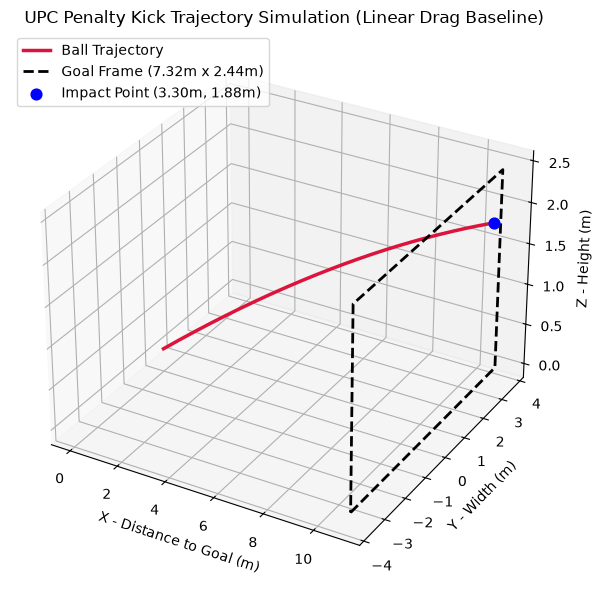

In [32]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Plot simulated trajectory
ax.plot(x, y, z, color='crimson', lw=2.5, label='Ball Trajectory')

# Plot goal frame rectangle at x = 11 m
goal_y = [-3.66, 3.66, 3.66, -3.66, -3.66]
goal_z = [0.0, 0.0, 2.44, 2.44, 0.0]
ax.plot([11]*5, goal_y, goal_z, color='black', lw=2, linestyle='--', label='Goal Frame (7.32m x 2.44m)')

# Highlight entry point
ax.scatter([11], [y_goal], [z_goal], color='blue', s=60, label=f'Impact Point ({y_goal:.2f}m, {z_goal:.2f}m)')

ax.set_xlabel('X - Distance to Goal (m)')
ax.set_ylabel('Y - Width (m)')
ax.set_zlabel('Z - Height (m)')
ax.set_title('UPC Penalty Kick Trajectory Simulation (Linear Drag Baseline)')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [33]:
v_sq = vx**2 + vy**2 + vz**2
E_kinetic = 0.5 * m * v_sq
E_potential = m * g * z
E_total = E_kinetic + E_potential

In [34]:
fig = plt.figure(figsize=(14, 5))

<Figure size 1400x500 with 0 Axes>

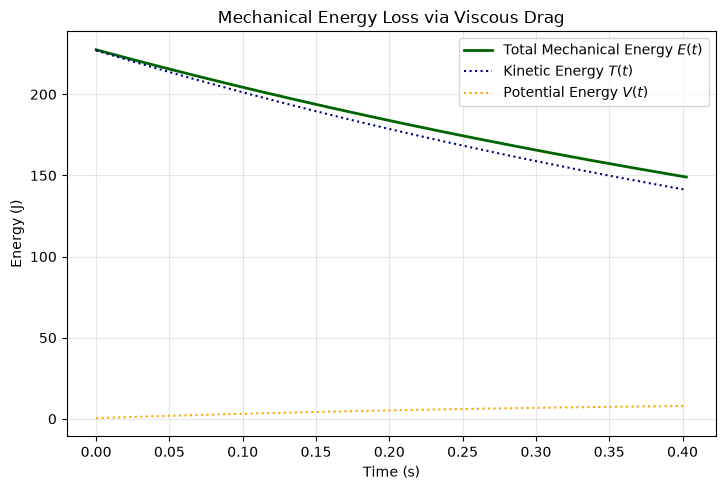

In [36]:
fig = plt.figure(figsize=(14, 5))


ax2 = fig.add_subplot(122)
ax2.plot(t, E_total, color='darkgreen', lw=2, label='Total Mechanical Energy $E(t)$')
ax2.plot(t, E_kinetic, color='navy', linestyle=':', label='Kinetic Energy $T(t)$')
ax2.plot(t, E_potential, color='orange', linestyle=':', label='Potential Energy $V(t)$')

ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Energy (J)')
ax2.set_title('Mechanical Energy Loss via Viscous Drag')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()